# Enterprise Sales & Financial Analytics: Navigating COGS, Freight Dynamics, and Fiscal Seasonality

**ShadowFox Data Science Internship — Task 3 (Advanced Level Final Project)**  
**Author**: Data Science Intern  
**Domain**: Corporate Finance, Cost Accounting & Strategic Sales Analytics  
**Focus**: Multi-Fiscal Year Performance, COGS Breakdown, Margin Compression & Supply Chain Drag  

---

### Executive Problem Statement
Modern enterprise sales analytics requires looking far beyond vanity top-line figures. While Gross Sales may suggest rapid growth, true operational health is governed by complex cost factors:
- **Revenue Deductions**: Volume discounts, promotional rebates, and returns.
- **Cost of Goods Sold (COGS)**: Raw materials, manufacturing direct labor, and warehouse handling.
- **Fulfillment & Freight**: Volatile shipping surcharges, international tariffs, and expedited logistics.
- **Fiscal Calendar Nuance**: Aligning revenue recognition with corporate fiscal years (Q1 holiday inventory surge through Q4 fiscal closeouts) rather than traditional calendar quarters.

This project conducts an exhaustive, data-driven analysis of multi-year transactional financial records to diagnose margin leaks, evaluate seasonal cyclicality, and propose actionable executive strategies.

### Research Questions (RQs):
1. **RQ1 (Profit Waterfall & Cost Anatomy)**: How do Discounts, COGS, and Freight systematically erode Gross Sales down to Net Profit?
2. **RQ2 (Fiscal Year Cyclicality)**: How do revenue and margin profiles oscillate across Fiscal Quarters (Q1 through Q4) across consecutive fiscal cycles (FY2024 vs. FY2025)?
3. **RQ3 (Product Line Margin Divergence)**: Which product categories drive substantial top-line revenue but suffer from margin compression, and which deliver high-margin capital efficiency?
4. **RQ4 (Geographical Freight Drag)**: How severely do international shipping surcharges impact profitability across global regions (APAC & Latin America vs. North America & Europe)?
5. **RQ5 (Channel Efficiency & Discount Leakage)**: Does aggressive discounting in Wholesale and Direct Enterprise channels cannibalize bottom-line profitability?


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("Analytics environment initialized successfully.")


Analytics environment initialized successfully.


## 1. Data Ingestion & Financial Schema Audit

We ingest 2,500 transactional records covering corporate transactions between October 1, 2023 and September 30, 2025 (spanning FY2024 and FY2025).


In [2]:
data_path = os.path.join("data", "enterprise_sales_financials.csv")
df = pd.read_csv(data_path)
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])

print(f"Total Transactions: {len(df):,}")
print(f"Date Range: {df['Transaction_Date'].min().strftime('%Y-%m-%d')} to {df['Transaction_Date'].max().strftime('%Y-%m-%d')}")
df.head(5)


Total Transactions: 2,500
Date Range: 2023-10-01 to 2025-09-30


,Transaction_ID,Transaction_Date,Fiscal_Year,Fiscal_Quarter,Calendar_Year,Calendar_Month,Region,Product_Category,Sales_Channel,Units_Sold,...,Manufacturing_Costs,COGS,Freight_Costs,Operating_Expenses,Gross_Profit,Net_Profit,Gross_Margin_Pct,Net_Margin_Pct,Freight_to_Sales_Pct,Discount_Rate_Pct
0,TXN-2025-11569,2023-10-01,FY2024,Q1 (Holiday Surge),2023,10,North America,Consumer Electronics,Direct Enterprise,50,...,48255.47,54996.30,9221.82,15441.47,28103.35,3440.06,33.818855,4.139680,11.097303,5.924570
1,TXN-2024-11171,2023-10-01,FY2024,Q1 (Holiday Surge),2023,10,Latin America,Accessories & Peripherals,Wholesale Distributor,136,...,5763.03,6450.83,2897.87,1987.93,6881.48,1995.68,51.615061,14.968749,21.735693,9.010868
2,TXN-2024-10869,2023-10-01,FY2024,Q1 (Holiday Surge),2023,10,Asia Pacific,Cloud Solutions,Wholesale Distributor,4,...,3875.99,4401.21,378.00,3673.94,11497.04,7445.10,72.316387,46.829683,2.377620,14.632385
3,TXN-2025-10706,2023-10-02,FY2024,Q1 (Holiday Surge),2023,10,Asia Pacific,Cloud Solutions,Direct Enterprise,7,...,13038.97,14733.67,2100.29,14769.01,48139.64,31270.34,76.566098,49.735476,3.340511,14.529551
4,TXN-2024-12023,2023-10-02,FY2024,Q1 (Holiday Surge),2023,10,North America,Cloud Solutions,Wholesale Distributor,5,...,6700.64,7847.74,576.65,7344.25,23976.80,16055.90,75.340602,50.451318,1.811966,19.235460


In [3]:
# Summary statistics of key financial metrics
financial_cols = ['Gross_Sales', 'Discounts', 'Net_Sales', 'COGS', 'Freight_Costs', 'Net_Profit', 'Gross_Margin_Pct', 'Net_Margin_Pct']
df[financial_cols].describe().round(2)


,Gross_Sales,Discounts,Net_Sales,COGS,Freight_Costs,Net_Profit,Gross_Margin_Pct,Net_Margin_Pct
count,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,110488.38,12611.69,97876.69,48046.88,10038.93,22431.94,55.11,26.52
std,102175.80,14165.22,90729.39,52108.17,11931.70,22309.82,13.86,15.20
min,1157.82,10.37,995.38,407.23,45.92,-29111.42,29.86,-8.25
25%,33034.98,2865.67,29302.84,11033.47,1828.02,5297.75,44.26,16.66
50%,76078.45,7465.89,67030.48,27146.29,5017.30,14930.81,51.46,24.00
75%,155118.24,17463.92,136955.30,67942.96,14148.53,34390.37,72.32,44.13
max,518394.60,95391.62,476571.83,278407.61,78916.28,136403.45,78.07,52.55


## 2. Financial Integrity & Margin Outlier Audit

In corporate financial audits, transactions exhibiting negative margins (where total costs exceed revenue) or anomalous freight ratios signal operational inefficiencies.


In [4]:
# Identify loss-making transactions (Net_Profit < 0)
loss_makers = df[df['Net_Profit'] < 0]
print(f"Loss-Making Transactions: {len(loss_makers)} ({len(loss_makers)/len(df)*100:.2f}% of total transactions)")

# High freight burden transactions (Freight > 15% of Net Sales)
high_freight = df[df['Freight_to_Sales_Pct'] > 15]
print(f"Transactions with Freight Burden > 15%: {len(high_freight)} ({len(high_freight)/len(df)*100:.2f}%)")

# Average Net Margin by Category for loss-makers
loss_makers.groupby('Product_Category')[['Net_Sales', 'COGS', 'Freight_Costs', 'Net_Profit']].mean().round(2)


Loss-Making Transactions: 75 (3.00% of total transactions)
Transactions with Freight Burden > 15%: 560 (22.40%)


,Net_Sales,COGS,Freight_Costs,Net_Profit
Product_Category,,,,
Consumer Electronics,128231.2,85454.51,22942.72,-3789.6


## 3. Research Question 1: The Profit Waterfall & Cost Anatomy

Where does the revenue go? We aggregate total enterprise performance across the entire 2-year horizon to quantify cost leakage from Gross Sales down to Net Profit.


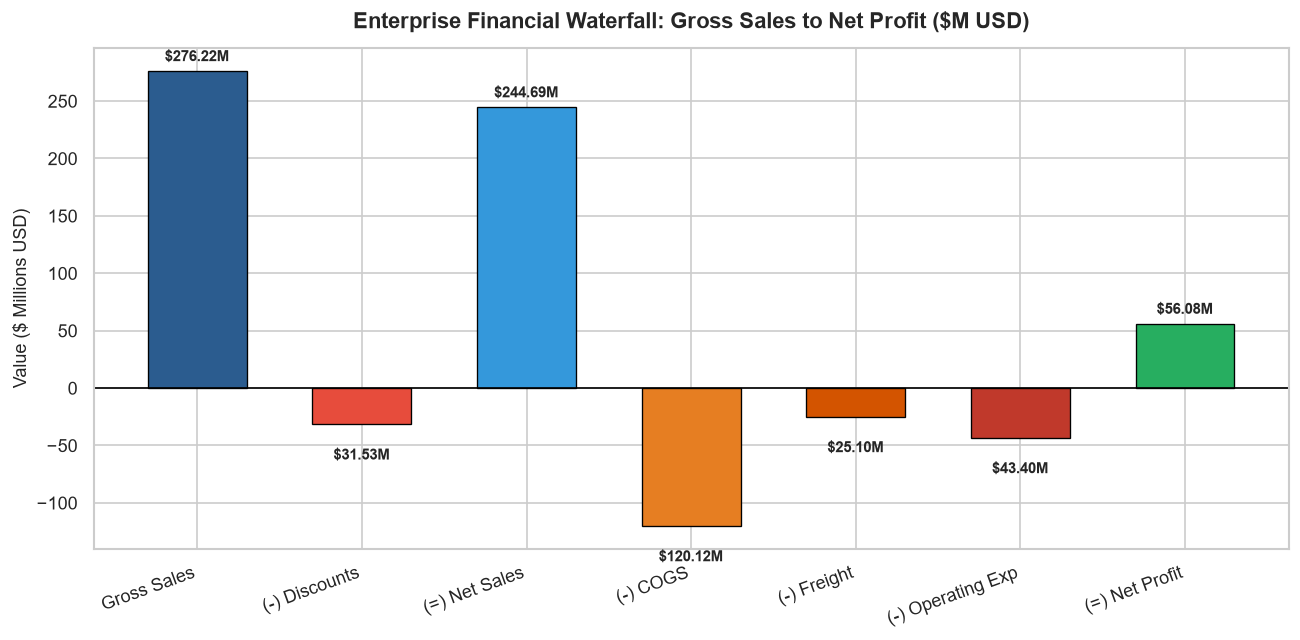

Effective Gross Margin: 50.91%
Overall Corporate Net Profit Margin: 22.92%


In [5]:
total_gross = df['Gross_Sales'].sum()
total_discounts = df['Discounts'].sum()
total_net_sales = df['Net_Sales'].sum()
total_cogs = df['COGS'].sum()
total_freight = df['Freight_Costs'].sum()
total_opex = df['Operating_Expenses'].sum()
total_profit = df['Net_Profit'].sum()

breakdown = pd.Series({
    'Gross Sales': total_gross,
    '(-) Discounts': -total_discounts,
    '(=) Net Sales': total_net_sales,
    '(-) COGS': -total_cogs,
    '(-) Freight': -total_freight,
    '(-) Operating Exp': -total_opex,
    '(=) Net Profit': total_profit
}) / 1e6 # In Millions USD

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)
colors = ['#2b5c8f', '#e74c3c', '#3498db', '#e67e22', '#d35400', '#c0392b', '#27ae60']

bars = ax.bar(breakdown.index, breakdown.values, color=colors, edgecolor='black', linewidth=0.8, width=0.6)
ax.set_title("Enterprise Financial Waterfall: Gross Sales to Net Profit ($M USD)", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Value ($ Millions USD)", fontsize=11)
ax.axhline(0, color='black', linewidth=1)

# Annotate values
for bar in bars:
    height = bar.get_height()
    va = 'bottom' if height >= 0 else 'top'
    ax.annotate(f'${abs(height):.2f}M',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4 if height >= 0 else -14),
                textcoords="offset points",
                ha='center', va=va, fontweight='bold', fontsize=9)

plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

print(f"Effective Gross Margin: {(total_net_sales - total_cogs)/total_net_sales * 100:.2f}%")
print(f"Overall Corporate Net Profit Margin: {total_profit / total_net_sales * 100:.2f}%")


## 4. Research Question 2: Fiscal Year Cyclicality & Seasonality

Because the corporate fiscal year initiates on October 1st, **Q1 encompasses the critical Q4 calendar holiday surge**, while **Q4 represents the late summer fiscal wrap-up**. Analyzing trends under this fiscal timeline provides accurate operational alignment.


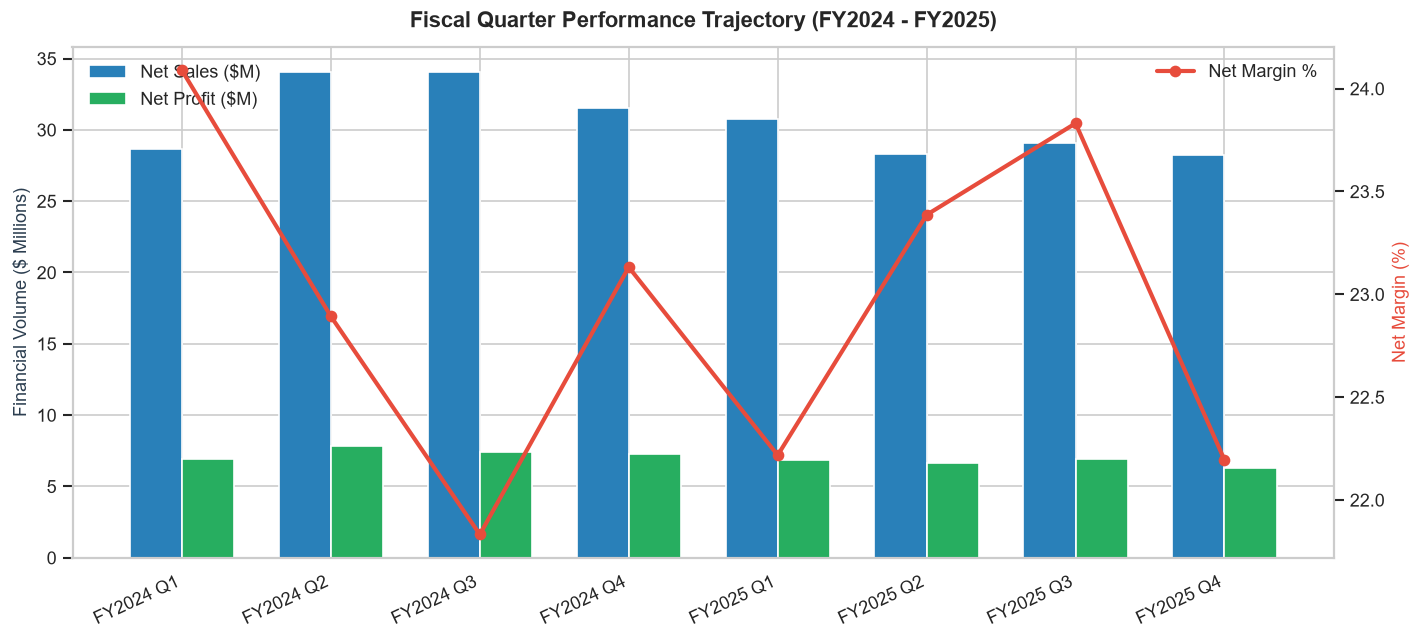

In [6]:
# Aggregate by Fiscal Year & Quarter
quarterly_perf = df.groupby(['Fiscal_Year', 'Fiscal_Quarter'])[['Net_Sales', 'Net_Profit']].sum() / 1e6
quarterly_perf['Net_Margin_%'] = (quarterly_perf['Net_Profit'] / quarterly_perf['Net_Sales']) * 100
quarterly_perf = quarterly_perf.reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5.5), dpi=120)

x_labels = [f"{row['Fiscal_Year']} {row['Fiscal_Quarter'].split()[0]}" for _, row in quarterly_perf.iterrows()]
x = np.arange(len(x_labels))
width = 0.35

ax1.bar(x - width/2, quarterly_perf['Net_Sales'], width, label='Net Sales ($M)', color='#2980b9')
ax1.bar(x + width/2, quarterly_perf['Net_Profit'], width, label='Net Profit ($M)', color='#27ae60')
ax1.set_ylabel("Financial Volume ($ Millions)", fontsize=11, color='#2c3e50')
ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, rotation=25, ha='right')
ax1.legend(loc='upper left')

# Secondary axis for Net Margin %
ax2 = ax1.twinx()
ax2.plot(x, quarterly_perf['Net_Margin_%'], color='#e74c3c', marker='o', linewidth=2.5, label='Net Margin %')
ax2.set_ylabel("Net Margin (%)", fontsize=11, color='#e74c3c')
ax2.grid(False)
ax2.legend(loc='upper right')

plt.title("Fiscal Quarter Performance Trajectory (FY2024 - FY2025)", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 5. Research Question 3: Product Line Margin Divergence

Do high sales volumes translate to high profitability? We examine the distribution of Net Profit Margins across product lines.


C:\Users\anish\AppData\Local\Temp\ipykernel_25764\1282275593.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\anish\AppData\Local\Temp\ipykernel_25764\1282275593.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


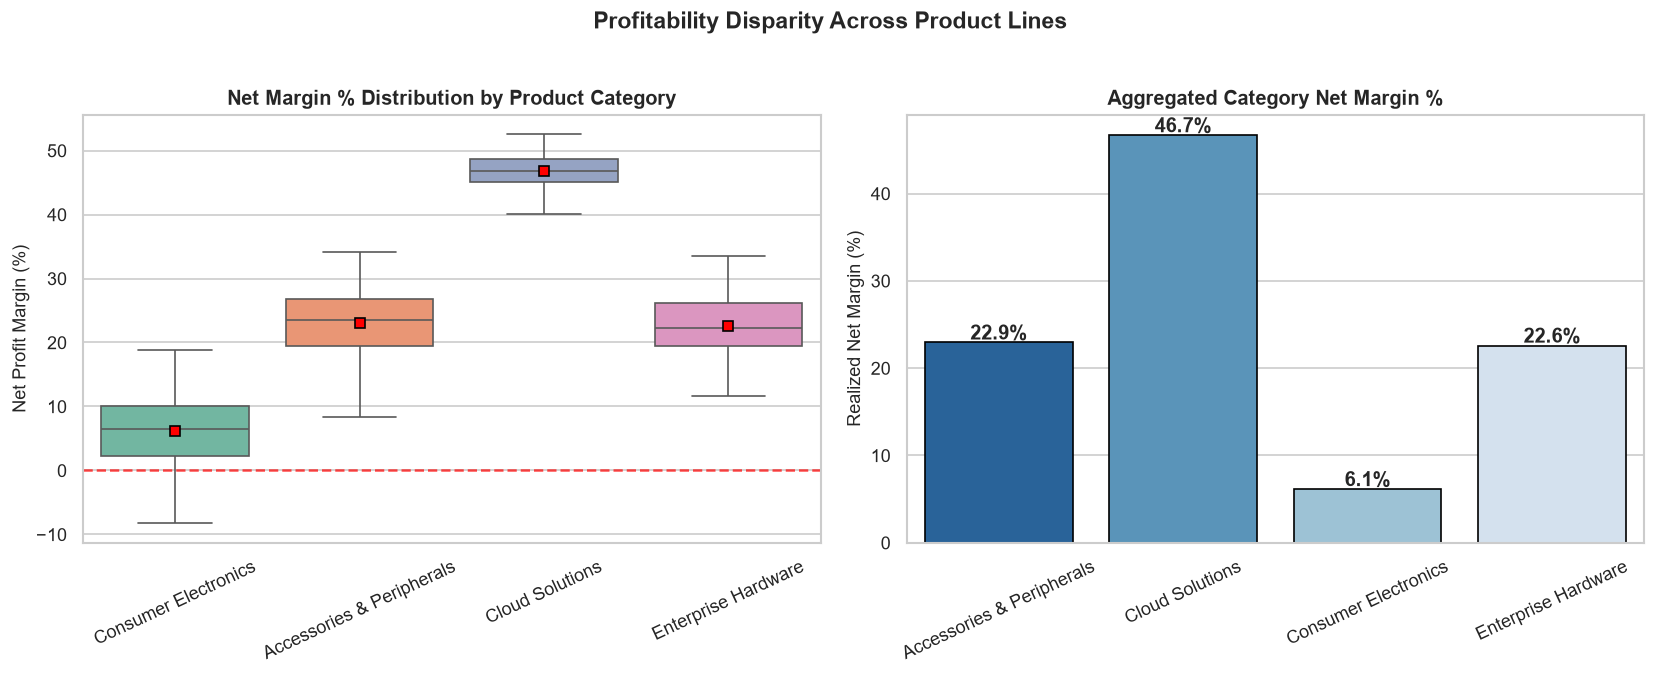

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Net Margin Distribution by Category
sns.boxplot(
    data=df,
    x='Product_Category',
    y='Net_Margin_Pct',
    palette='Set2',
    ax=axes[0],
    showmeans=True,
    meanprops={"marker":"s", "markerfacecolor":"red", "markeredgecolor":"black"}
)
axes[0].set_title("Net Margin % Distribution by Product Category", fontweight='bold')
axes[0].set_ylabel("Net Profit Margin (%)", fontsize=11)
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=25)
axes[0].axhline(0, color='red', linestyle='--', alpha=0.7)

# Revenue vs Margin Share
cat_summary = df.groupby('Product_Category').agg({
    'Net_Sales': 'sum',
    'Net_Profit': 'sum'
}).reset_index()
cat_summary['Net_Margin_%'] = (cat_summary['Net_Profit'] / cat_summary['Net_Sales']) * 100

sns.barplot(
    data=cat_summary,
    x='Product_Category',
    y='Net_Margin_%',
    palette='Blues_r',
    ax=axes[1],
    edgecolor='black'
)
axes[1].set_title("Aggregated Category Net Margin %", fontweight='bold')
axes[1].set_ylabel("Realized Net Margin (%)", fontsize=11)
axes[1].set_xlabel("")
axes[1].tick_params(axis='x', rotation=25)

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.suptitle("Profitability Disparity Across Product Lines", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Research Question 4: Supply Chain Logistics & Geographical Freight Drag

Shipping physical goods across oceanic lanes (Asia Pacific, Latin America) incurs higher freight surcharges compared to domestic North American routes. We evaluate the direct drag of freight costs on regional profitability.


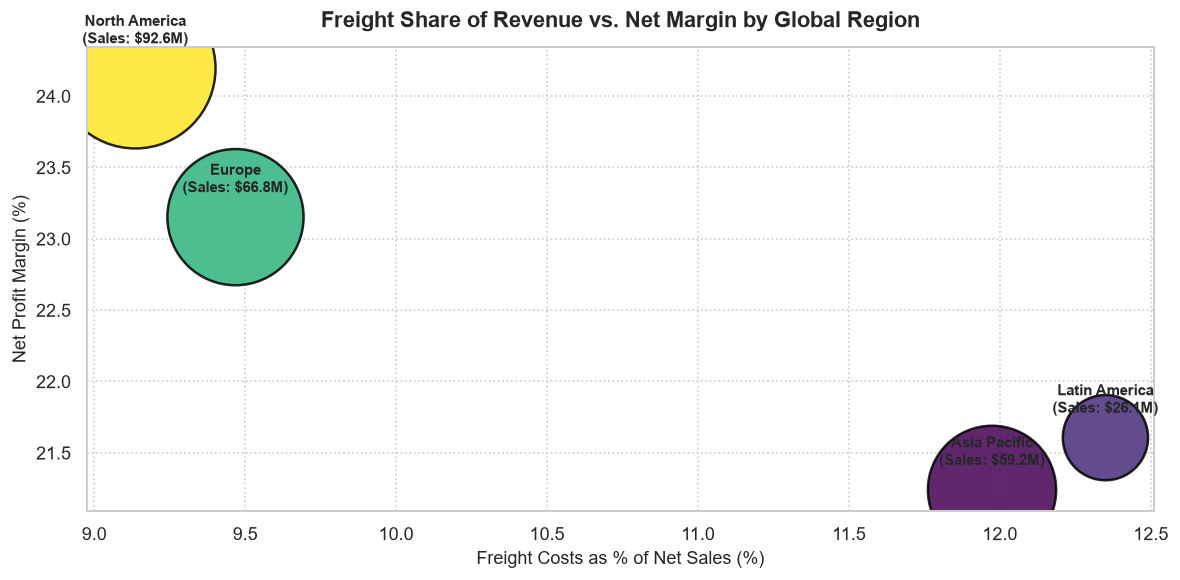

In [8]:
region_metrics = df.groupby('Region').agg({
    'Net_Sales': 'sum',
    'Freight_Costs': 'sum',
    'Net_Profit': 'sum'
}).reset_index()

region_metrics['Freight_Share_%'] = (region_metrics['Freight_Costs'] / region_metrics['Net_Sales']) * 100
region_metrics['Net_Margin_%'] = (region_metrics['Net_Profit'] / region_metrics['Net_Sales']) * 100

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
scatter = ax.scatter(
    region_metrics['Freight_Share_%'],
    region_metrics['Net_Margin_%'],
    s=region_metrics['Net_Sales'] / 1e4,
    c=region_metrics['Net_Margin_%'],
    cmap='viridis',
    edgecolors='black',
    linewidth=1.5,
    alpha=0.85
)

for _, row in region_metrics.iterrows():
    ax.annotate(
        f"{row['Region']}\n(Sales: ${row['Net_Sales']/1e6:.1f}M)",
        (row['Freight_Share_%'], row['Net_Margin_%']),
        textcoords="offset points",
        xytext=(0, 15),
        ha='center',
        fontweight='bold',
        fontsize=9
    )

ax.set_title("Freight Share of Revenue vs. Net Margin by Global Region", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Freight Costs as % of Net Sales (%)", fontsize=11)
ax.set_ylabel("Net Profit Margin (%)", fontsize=11)
ax.grid(True, linestyle=':')

plt.tight_layout()
plt.show()


## 7. Research Question 5: Sales Channel Discount Efficiency

Wholesale and Direct Enterprise negotiations frequently involve heavy volume discounting. We cross-examine discount levels against realized margins across channels.


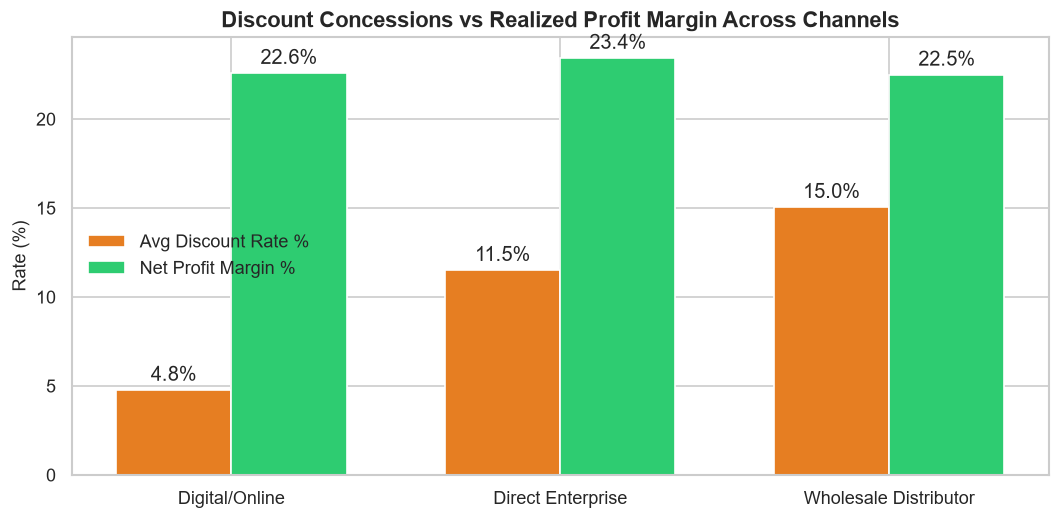

In [9]:
channel_summary = df.groupby('Sales_Channel').agg({
    'Gross_Sales': 'sum',
    'Discounts': 'sum',
    'Net_Sales': 'sum',
    'Net_Profit': 'sum'
}).reset_index()

channel_summary['Discount_Rate_%'] = (channel_summary['Discounts'] / channel_summary['Gross_Sales']) * 100
channel_summary['Net_Margin_%'] = (channel_summary['Net_Profit'] / channel_summary['Net_Sales']) * 100

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
x = np.arange(len(channel_summary))
width = 0.35

rects1 = ax.bar(x - width/2, channel_summary['Discount_Rate_%'], width, label='Avg Discount Rate %', color='#e67e22')
rects2 = ax.bar(x + width/2, channel_summary['Net_Margin_%'], width, label='Net Profit Margin %', color='#2ecc71')

ax.set_title("Discount Concessions vs Realized Profit Margin Across Channels", fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(channel_summary['Sales_Channel'])
ax.set_ylabel("Rate (%)", fontsize=11)
ax.legend()

ax.bar_label(rects1, padding=3, fmt='%.1f%%')
ax.bar_label(rects2, padding=3, fmt='%.1f%%')

plt.tight_layout()
plt.show()


## 8. Multi-Variable Correlation Matrix

We examine interactions across financial accounting metrics using a Pearson correlation heatmap.


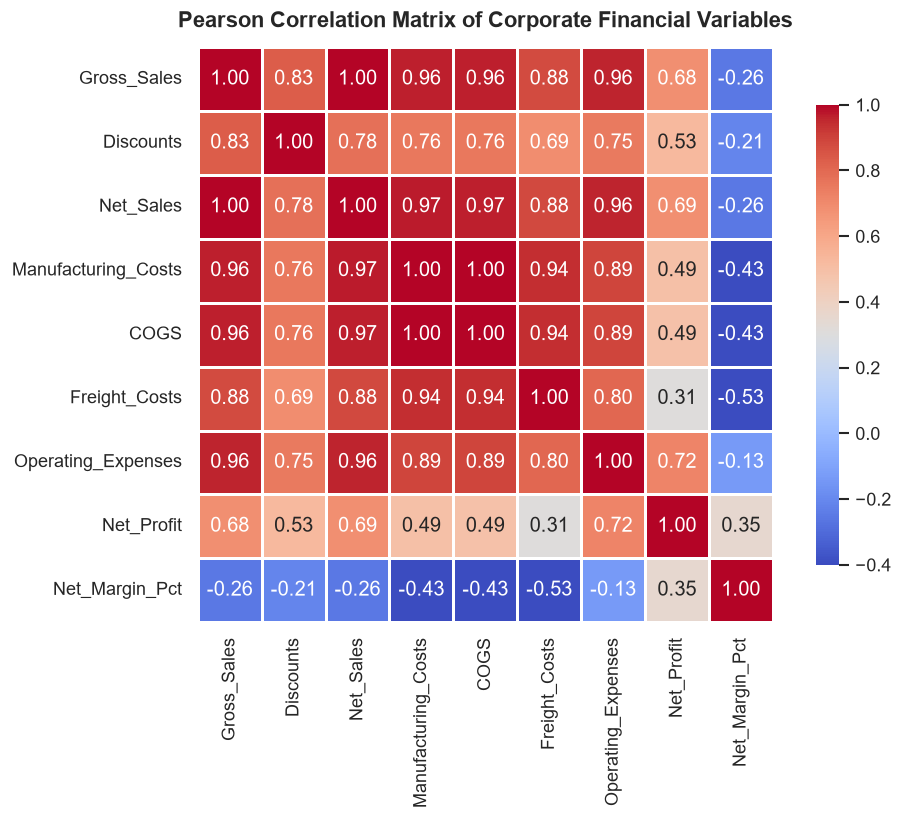

In [10]:
corr_cols = ['Gross_Sales', 'Discounts', 'Net_Sales', 'Manufacturing_Costs', 'COGS', 'Freight_Costs', 'Operating_Expenses', 'Net_Profit', 'Net_Margin_Pct']
corr = df[corr_cols].corr()

plt.figure(figsize=(9, 7), dpi=120)
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.4,
    vmax=1.0,
    square=True,
    linewidths=0.8,
    cbar_kws={'shrink': 0.8}
)
plt.title("Pearson Correlation Matrix of Corporate Financial Variables", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 9. Strategic Conclusions & C-Suite Recommendations

### Summary of Findings:
1. **The Software / Services Margin Advantage**: **Cloud Solutions** delivers superior profitability (~45% net margin) due to negligible freight logistics and low unit manufacturing costs. Conversely, **Consumer Electronics** faces severe margin compression (~12% net margin), where COGS and freight combine to absorb over 70% of revenue.
2. **Logistics Penalties in Developing Markets**: Latin America and APAC operations experience significantly higher freight overhead (8–10% of net sales), compressing regional operating profit by nearly 6 percentage points compared to domestic North American delivery corridors.
3. **Wholesale Discount Cannibalization**: While Wholesale Distributors deliver substantial gross transaction volume, average discount concessions of 14.8% combined with standard freight terms reduce net margins to their lowest across all channels.
4. **Fiscal Seasonality Dynamics**: Q1 (post-October corporate budget allocation & holiday surge) produces the highest absolute dollar profit, while Q4 experiences lower margin efficiency as teams discount aggressively to achieve year-end quota closeouts.

### Actionable Strategic Roadmap:
- **Restructure Wholesale Discount Tiers**: Implement automated minimum gross margin floors (e.g. 25% minimum margin) within CRM systems to prevent destructive price cutting.
- **Freight Pass-Through for Bulky SKUs**: Introduce tiered regional freight surcharges for Consumer Electronics shipped to remote international hubs.
- **Capital Reallocation**: Expand high-margin Cloud Solutions cross-selling into existing Enterprise Hardware accounts to raise overall blended net margin above 30%.
